# PPO BTC trading — Ali


All project code is defined here: Binance downloads, features, environment wrappers, actor and critic, PPO updates, training, hyperparameter selection, ensembles, regression tests, evaluation, tables, and plots.


Training data begins April 1, 2020 UTC, with seven earlier days downloaded for feature warmup. The action space is `[-1, -0.75, -0.5, -0.25, 0, 0.25, 0.5, 0.75, 1]` (cash is index 4). Evaluation remains August 17–September 17, 2026, end exclusive. It is a reused holdout from the earlier project, not a new independent test.


## 1. Kernel check, dependencies, and configuration



In [1]:
import sys
print('Kernel ready:', sys.version.split()[0], flush=True)
print('Interpreter:', sys.executable, flush=True)

# Optional one-time installation into a fresh Python 3.12 kernel:
# Uncomment the next line only when the required packages are missing, then restart the kernel.
# %pip install numpy==1.26.4 torch==2.2.2 "gymnasium[classic-control]==1.2.1" gym-trading-env==0.3.5 pandas==2.3.3 matplotlib==3.10.7 certifi==2025.10.5 pyecharts==2.0.9 "cloudpickle>=3,<4" "ipykernel>=6,<8" cryptography==44.0.3


Kernel ready: 3.12.14
Interpreter: /Users/alivakof/Documents/Codex/python-data-science/.venv/bin/python


In [2]:
from __future__ import annotations
from concurrent.futures import ThreadPoolExecutor, as_completed, wait, FIRST_COMPLETED
from dataclasses import dataclass, asdict, replace
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile
import hashlib
import json
import ssl
import subprocess
import sys
import time
import unittest

import certifi
import cloudpickle
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.distributions import Categorical
import gymnasium as gym
import gym_trading_env
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")

torch.set_num_threads(1)
COLUMNS = ['open', 'high', 'low', 'close', 'volume']
TRAIN_START = pd.Timestamp('2020-04-01', tz='UTC')
DATA_START = TRAIN_START - pd.Timedelta(days=7)
EVAL_START = pd.Timestamp('2026-08-17', tz='UTC')
EVAL_END = pd.Timestamp('2026-09-17', tz='UTC')
FOLDS = [(EVAL_START-pd.Timedelta(days=d+30), EVAL_START-pd.Timedelta(days=d))
         for d in [180, 120, 60, 0]]
SEEDS = [23, 42, 71]
POSITIONS = (-1., -.75, -.5, -.25, 0., .25, .5, .75, 1.)
SCREEN_STEPS = 16384
CONFIRM_STEPS = 49152
AGGREGATIONS = ('mean_probability', 'unanimous')
WORKERS = 3

In [3]:
print('Imports complete | Python:', sys.version.split()[0], '| PyTorch:', torch.__version__, flush=True)
print('Training storage: memory only; market data: direct HTTPS downloads from Binance.', flush=True)
print('The final submission cell exports evaluation_results.csv.', flush=True)
print('Training workers:', WORKERS, '| Positions:', POSITIONS, flush=True)
assert POSITIONS[4] == 0 and len(POSITIONS) == 9

Imports complete | Python: 3.12.14 | PyTorch: 2.2.2
Training storage: memory only; market data: direct HTTPS downloads from Binance.
The final submission cell exports evaluation_results.csv.
Training workers: 3 | Positions: (-1.0, -0.75, -0.5, -0.25, 0.0, 0.25, 0.5, 0.75, 1.0)


## 2. Download Binance candles into memory

Download 94 monthly/daily BTCUSDT hourly archives and their SHA-256 checksums. No ZIP, CSV, pickle, or manifest is saved or read locally. `raw.attrs` holds source URLs, checksums, missing-hour information, and a data fingerprint. The downloader reports progress and uses bounded network retries.

Missing source hours are recorded; synthetic candles are never inserted. Features restart after gaps and training episodes cannot cross gaps. Binance changed spot timestamps to microseconds starting in 2025; parsing supports both units. [Binance public-data documentation](https://github.com/binance/binance-public-data).

In [4]:
def validate(frame, start=DATA_START, end=EVAL_END, declared_missing=()):
    frame = frame.copy()
    frame.index = pd.to_datetime(frame.index, utc=True)
    frame = frame.sort_index()[COLUMNS].astype(float)
    expected = pd.date_range(start, end, freq='h', inclusive='left')
    declared = pd.DatetimeIndex(pd.to_datetime(list(declared_missing), utc=True))
    if not frame.index.equals(expected.difference(declared)):
        missing = expected.difference(frame.index)
        raise ValueError(f'Incomplete/duplicate hourly history: {len(missing)} missing; '
                         f'first missing: {list(missing[:5])}')
    prices = frame[['open', 'high', 'low', 'close']]
    if (not np.isfinite(frame.to_numpy()).all() or (prices <= 0).any().any()
            or (frame.volume < 0).any()
            or (frame.high < prices.max(axis=1)).any()
            or (frame.low > prices.min(axis=1)).any()):
        raise ValueError('Invalid OHLCV values')
    return frame

def fetch(url):
    context = ssl.create_default_context(cafile=certifi.where())
    for attempt in range(3):
        try:
            with urlopen(url, context=context, timeout=30) as response:
                return response.read()
        except OSError:
            if attempt == 2:
                raise
            time.sleep(attempt + 1)

def parse_archive(payload):
    with ZipFile(BytesIO(payload)) as archive:
        names = [name for name in archive.namelist() if name.endswith('.csv')]
        if len(names) != 1:
            raise ValueError('Expected one candle CSV per archive')
        frame = pd.read_csv(archive.open(names[0]), header=None, usecols=range(6))
    timestamps = frame.pop(0).astype('int64')
    # Binance changed spot archives from milliseconds to microseconds in 2025.
    unit = 'us' if timestamps.iloc[0] >= 10**15 else 'ms'
    frame.columns = COLUMNS
    frame.index = pd.DatetimeIndex(pd.to_datetime(timestamps, unit=unit, utc=True), name='date_open')
    return frame.astype(float)

In [5]:
def archive_requests(start=DATA_START, end=EVAL_END):
    """Prefer complete monthly archives; use daily files for a partial final month."""
    if start >= end or start != start.normalize() or end != end.normalize():
        raise ValueError('Expected increasing UTC whole-day boundaries')
    months = pd.period_range(start.tz_localize(None), (end-pd.Timedelta(hours=1)).tz_localize(None), freq='M')
    requests = []
    for month in months:
        first = month.start_time.tz_localize('UTC')
        following = (month+1).start_time.tz_localize('UTC')
        if following <= end:
            requests.append(('monthly', str(month)))
        else:
            for day in pd.date_range(max(first,start), end, freq='D', inclusive='left'):
                requests.append(('daily', day.strftime('%Y-%m-%d')))
    return requests


def download_archive(request):
    frequency, period = request
    filename = f'BTCUSDT-1h-{period}.zip'
    url = f'https://data.binance.vision/data/spot/{frequency}/klines/BTCUSDT/1h/{filename}'
    checksum = fetch(url + '.CHECKSUM').decode().split()[0]
    payload = fetch(url)
    digest = hashlib.sha256(payload).hexdigest()
    if digest != checksum:
        raise ValueError(f'Checksum mismatch for {filename}')
    return parse_archive(payload), {'url':url, 'sha256':digest}


def download_data():
    requests = archive_requests()
    started = time.perf_counter()
    print(f'Downloading {len(requests)} Binance archives into memory...', flush=True)
    results = []
    with ThreadPoolExecutor(max_workers=4) as pool:
        pending = {pool.submit(download_archive, request) for request in requests}
        while pending:
            completed, pending = wait(pending, timeout=10, return_when=FIRST_COMPLETED)
            for future in completed:
                results.append(future.result())
            elapsed = time.perf_counter() - started
            if not completed or len(results) % 10 == 0 or not pending:
                print(f'Downloaded and verified {len(results)}/{len(requests)} archives | {elapsed:.1f}s', flush=True)
    results.sort(key=lambda item:item[1]['url'])
    frame = pd.concat([part for part,_ in results]).sort_index()
    frame = frame.loc[(frame.index >= DATA_START) & (frame.index < EVAL_END)]
    expected = pd.date_range(DATA_START,EVAL_END,freq='h',inclusive='left')
    missing = [str(x) for x in expected.difference(frame.index)]
    frame = validate(frame, declared_missing=missing)
    frame.attrs.update(missing_hours=missing, archives=[record for _,record in results],
                       downloaded_at=str(pd.Timestamp.now(tz='UTC')),
                       sha256=hashlib.sha256(pd.util.hash_pandas_object(frame,index=True).values.tobytes()).hexdigest())
    return frame


def load_data():
    """Download a fresh dataset; retained as the project's public data entry point."""
    return download_data()

In [6]:
raw = load_data()
print(f'{len(raw):,} source candles: {raw.index.min()} to {raw.index.max()}')
print('Documented missing hours:', len(raw.attrs.get('missing_hours',[])))
display(raw.head(3))
print('Source archives verified:', len(raw.attrs['archives']))
print('Dataset SHA-256:', raw.attrs['sha256'])

Downloaded and verified 10/94 archives | 2.9s
Downloaded and verified 20/94 archives | 5.3s
Downloaded and verified 30/94 archives | 7.7s
Downloaded and verified 40/94 archives | 9.7s
Downloaded and verified 50/94 archives | 12.6s
Downloaded and verified 60/94 archives | 14.3s
Downloaded and verified 70/94 archives | 17.3s
Downloaded and verified 80/94 archives | 19.3s
Downloaded and verified 90/94 archives | 21.5s
Downloaded and verified 94/94 archives | 22.0s
56,784 source candles: 2020-03-25 00:00:00+00:00 to 2026-09-16 23:00:00+00:00
Documented missing hours: 24


,open,high,low,close,volume
date_open,,,,,
2020-03-25 00:00:00+00:00,6744.69,6746.70,6614.98,6699.98,5805.447179
2020-03-25 01:00:00+00:00,6699.98,6720.11,6593.35,6605.55,3472.820674
2020-03-25 02:00:00+00:00,6606.09,6652.63,6535.10,6594.58,4461.035762


Source archives verified: 94
Dataset SHA-256: aeb2d34131f54034eae8608a3ac3ea27d6354030029829f26d0f3dd624bd7590


## 3. Causal features and environment

Features use only the completed current candle and previous candles. Each fit learns its scaler from its own training partition. Momentum features need 168 hours of warm-up after each source gap. Environments start at portfolio value 1,000 in cash, with a 0.0001 trading fee and 0.000003 hourly borrowing-interest parameter. Close-price execution omits spread, slippage, and latency.

Random training episodes contain at most 720 consecutive candles. Short continuous segments cannot supply a full window; not every candle is guaranteed to be sampled. Evaluation uses every candle in its fixed continuous window.

In [7]:
def shared_add_features(raw, kind='momentum'):
    """Every value uses only the candle at t and earlier candles."""
    df = raw[['open','high','low','close','volume']].copy()
    if kind == 'basic':
        df['feature_close'] = df.close.pct_change()
        for c in ['open','high','low']:
            df['feature_'+c] = df[c]/df.close
        df['feature_volume'] = df.volume/df.volume.rolling(168).max().clip(lower=1e-8)
    elif kind == 'momentum':
        log_close = np.log(df.close)
        returns = log_close.diff()
        for lag in [1, 6, 24, 72, 168]:
            df[f'feature_return_{lag}'] = log_close.diff(lag)
        for window in [24, 168]:
            df[f'feature_volatility_{window}'] = returns.rolling(window).std()
        for window in [24, 72, 168]:
            df[f'feature_trend_{window}'] = df.close/df.close.ewm(span=window, adjust=False, min_periods=window).mean()-1
        df['feature_range'] = (df.high-df.low)/df.close
        df['feature_body'] = df.close/df.open-1
        df['feature_volume'] = np.log((df.volume+1e-8)/(df.volume.rolling(168).mean()+1e-8))
    else:
        raise ValueError(kind)
    return df.replace([np.inf, -np.inf], np.nan).dropna()

def add_features(raw, kind='momentum'):
    """Restart rolling features at missing hours; never impute market candles."""
    segments = raw.index.to_series().diff().ne(pd.Timedelta(hours=1)).cumsum()
    return pd.concat([shared_add_features(part, kind) for _, part in raw.groupby(segments)])

def make_env(frame, positions, duration='max'):
    frame = frame.copy()
    frame.index = frame.index.tz_convert('UTC').tz_localize(None)
    return gym.make('TradingEnv', name='BTCUSDT', df=frame, positions=list(positions),
                    initial_position=0, trading_fees=.0001, borrow_interest_rate=.000003,
                    max_episode_duration=duration, verbose=0)

class TrainingWindowEnv(gym.Wrapper):
    """Sample complete hourly windows; neither features nor episodes cross gaps."""
    def __init__(self, frame, positions, duration):
        self.frame, self.positions, self.duration = frame, positions, duration
        times = frame.index
        # Compare elapsed times directly; pandas datetime storage units can differ.
        # Ordered hourly timestamps make endpoint spacing sufficient to reject gaps.
        if not frame.index.is_monotonic_increasing or not frame.index.is_unique:
            raise ValueError('Training timestamps must be ordered and unique')
        self.starts = np.flatnonzero(times[duration-1:] - times[:len(times)-duration+1]
                                     == (duration-1)*pd.Timedelta(hours=1))
        if not len(self.starts):
            raise ValueError('No continuous hourly training window of the requested duration')
        super().__init__(make_env(frame.iloc[:duration], positions))

    def reset(self, *, seed=None, options=None):
        start = int(np.random.choice(self.starts))
        self.env.close()
        self.env = make_env(self.frame.iloc[start:start+self.duration], self.positions)
        return self.env.reset(seed=seed, options=options)

In [8]:
def rollout(policy, frame, positions=None, return_trace=False):
    positions = policy.positions if positions is None else positions
    env = make_env(frame, positions)
    state, _ = env.reset(seed=123)
    records = [dict(timestamp=frame.index[0], portfolio_value=1000., position=0., reward=0.)]
    try:
        done = False
        while not done:
            action = policy.choose_action_eval(state)
            state, reward, terminated, truncated, info = env.step(action)
            records.append(dict(timestamp=frame.index[len(records)],
                                portfolio_value=float(info['portfolio_valuation']),
                                position=float(positions[action]), reward=float(reward)))
            done = terminated or truncated
    finally:
        env.close()
    trace = pd.DataFrame(records)
    values = trace.portfolio_value.to_numpy()
    market_return = float(frame.close.iloc[-1]/frame.close.iloc[0]-1)
    ret = values[-1]/values[0]-1
    dd = float(np.min(values/np.maximum.accumulate(values)-1))
    metrics = dict(portfolio_return=ret, market_return=market_return,
                   excess_return=ret-market_return, max_drawdown=dd,
                   log_return=float(np.log(max(values[-1]/values[0],1e-12))),
                   action_changes=int(np.count_nonzero(np.diff(trace.position))),
                   steps=len(trace)-1, total_reward=float(trace.reward.sum()))
    return (metrics, trace) if return_trace else metrics

class ConstantPolicy:
    def __init__(self, positions, position):
        self.positions = positions
        self.action = positions.index(position)
    def choose_action_eval(self, state):
        return self.action

In [9]:
pre_evaluation = raw.loc[raw.index < EVAL_START]
training_frame = add_features(pre_evaluation).loc[lambda frame: frame.index >= TRAIN_START]
assert training_frame.index.min() == TRAIN_START and training_frame.index.max() < EVAL_START
split_rows = []
for feature_kind in ['basic','momentum']:
    featured = add_features(pre_evaluation,feature_kind)
    for fold,(start,end) in enumerate(FOLDS):
        train = featured.loc[(featured.index >= TRAIN_START)&(featured.index < start)]
        validation = featured.loc[(featured.index >= start)&(featured.index < end)]
        assert train.index.max() < validation.index.min() and validation.index.max() < EVAL_START
        assert len(validation) == 720
        assert (validation.index[1:]-validation.index[:-1] == pd.Timedelta(hours=1)).all()
        split_rows.append({'features':feature_kind,'fold':fold,'training_rows':len(train),
                           'validation_start':start,'validation_end_exclusive':end})
display(pd.DataFrame(split_rows))
print(f'{len(training_frame):,} usable momentum training candles')

,features,fold,training_rows,validation_start,validation_end_exclusive
0,basic,0,48961,2026-01-19 00:00:00+00:00,2026-02-18 00:00:00+00:00
1,basic,1,50401,2026-03-20 00:00:00+00:00,2026-04-19 00:00:00+00:00
2,basic,2,51841,2026-05-19 00:00:00+00:00,2026-06-18 00:00:00+00:00
3,basic,3,53281,2026-07-18 00:00:00+00:00,2026-08-17 00:00:00+00:00
4,momentum,0,48951,2026-01-19 00:00:00+00:00,2026-02-18 00:00:00+00:00
5,momentum,1,50391,2026-03-20 00:00:00+00:00,2026-04-19 00:00:00+00:00
6,momentum,2,51831,2026-05-19 00:00:00+00:00,2026-06-18 00:00:00+00:00
7,momentum,3,53271,2026-07-18 00:00:00+00:00,2026-08-17 00:00:00+00:00


53,991 usable momentum training candles


## 4. PPO actor, critic, and loss

The actor is categorical over the nine discrete target positions. Separate two-layer networks model action probabilities and state value. PPO reuses each fresh rollout for several minibatch epochs with probability-ratio clipping, normalized advantages, gradient clipping, and an approximate-KL stopping threshold. It then discards that rollout.

The optimized loss is the negative clipped policy objective plus weighted value error minus weighted policy entropy. GAE bootstraps time-limit truncations from the final observation, stops recursion at resets, and gives genuine terminal states zero bootstrap.

Reference: [Schulman et al., Proximal Policy Optimization Algorithms](https://arxiv.org/abs/1707.06347).

In [10]:
@dataclass(frozen=True)
class PPOConfig:
    name: str
    features: str = 'momentum'
    positions: tuple = POSITIONS
    hidden: int = 64
    lr: float = 3e-4
    gamma: float = .99
    gae_lambda: float = .95
    clip_range: float = .2
    entropy_coef: float = .01
    value_coef: float = .5
    max_grad_norm: float = .5
    target_kl: float = .02
    epochs: int = 6
    batch_size: int = 256
    n_envs: int = 4
    rollout_steps: int = 256
    reward_scale: float = 100.
    turnover_penalty: float = 0.
    anneal_lr: bool = True

CONFIGS = [
    PPOConfig('ppo_baseline', features='basic', entropy_coef=0., anneal_lr=False),
    PPOConfig('ppo_momentum'),
    PPOConfig('ppo_cautious', lr=1e-4, clip_range=.1, entropy_coef=.005),
    PPOConfig('ppo_short_horizon', gamma=.95, gae_lambda=.90),
    PPOConfig('ppo_turnover', gamma=.95, turnover_penalty=.0003),
    PPOConfig('ppo_low_turnover', turnover_penalty=.0001),
    PPOConfig('ppo_exploration', entropy_coef=.03, turnover_penalty=.0001),
]

def config_from_dict(data):
    return PPOConfig(**{**data, 'positions': tuple(data['positions'])})

In [11]:
def compute_gae(rewards, values, next_values, terminated, done, gamma, gae_lambda):
    """Time-major [T, N] GAE; bootstrap truncations but never cross resets.

    `next_values` must refer to the transition's final observation, not the
    reset observation. A bankruptcy/true terminal has no future value.
    """
    arrays = [np.asarray(a, np.float32) for a in
              (rewards, values, next_values, terminated, done)]
    rewards, values, next_values, terminated, done = arrays
    if rewards.ndim != 2 or any(a.shape != rewards.shape for a in arrays):
        raise ValueError('GAE inputs must have matching [time, environment] shapes')
    advantages = np.zeros_like(rewards)
    carry = np.zeros(rewards.shape[1], np.float32)
    for t in reversed(range(len(rewards))):
        delta = rewards[t] + gamma * (1-terminated[t]) * next_values[t] - values[t]
        carry = delta + gamma * gae_lambda * (1-done[t]) * carry
        advantages[t] = carry
    return advantages, advantages + values

def clipped_policy_loss(log_probs, old_log_probs, advantages, clip_range):
    ratio = (log_probs-old_log_probs).exp()
    unclipped = ratio * advantages
    clipped = ratio.clamp(1-clip_range, 1+clip_range) * advantages
    return -torch.minimum(unclipped, clipped).mean()

class ActorCritic(nn.Module):
    def __init__(self, dimensions, actions, hidden):
        super().__init__()
        # Separate networks prevent value regression from dominating actor features.
        def mlp(outputs, output_gain):
            net = nn.Sequential(nn.Linear(dimensions, hidden), nn.Tanh(),
                                nn.Linear(hidden, hidden), nn.Tanh(),
                                nn.Linear(hidden, outputs))
            for layer in net:
                if isinstance(layer, nn.Linear):
                    nn.init.orthogonal_(layer.weight, np.sqrt(2))
                    nn.init.zeros_(layer.bias)
            nn.init.orthogonal_(net[-1].weight, output_gain)
            return net
        self.actor = mlp(actions, .01)
        self.critic = mlp(1, 1.)

    def forward(self, states):
        return Categorical(logits=self.actor(states)), self.critic(states).squeeze(-1)

class PPOAgent:
    def __init__(self, config, columns, mean, std, seed=23):
        self.config, self.columns, self.seed = config, list(columns), seed
        self.positions = tuple(config.positions)
        self.mean = np.asarray(mean, np.float32)
        self.std = np.asarray(std, np.float32)
        if len(self.mean) != len(self.columns)+2 or np.any(self.std <= 0):
            raise ValueError('Scaler must match static features plus two position features')
        torch.manual_seed(seed)
        self.rng = np.random.default_rng(seed)
        self.network = ActorCritic(len(self.mean), len(self.positions), config.hidden)
        self.optimizer = torch.optim.Adam(self.network.parameters(), lr=config.lr, eps=1e-5)
        self.updates = 0

    def encode(self, states):
        encoded = np.clip((np.asarray(states, np.float32)-self.mean)/self.std, -8, 8)
        if not np.isfinite(encoded).all():
            raise FloatingPointError('Non-finite observation')
        return encoded

    def probabilities(self, state):
        with torch.no_grad():
            distribution, _ = self.network(torch.from_numpy(self.encode(state)))
        return distribution.probs.numpy()

    def choose_action_eval(self, state):
        return int(self.probabilities(state).argmax())

    def update(self, states, actions, old_log_probs, advantages, returns, progress):
        cfg = self.config
        states = torch.as_tensor(states.reshape(-1, len(self.mean)))
        actions = torch.as_tensor(actions.reshape(-1), dtype=torch.long)
        old_log_probs = torch.as_tensor(old_log_probs.reshape(-1))
        advantages = torch.as_tensor(advantages.reshape(-1))
        advantages = (advantages-advantages.mean()) / (advantages.std(unbiased=False)+1e-8)
        returns = torch.as_tensor(returns.reshape(-1))
        lr = cfg.lr * (max(.1, 1-progress) if cfg.anneal_lr else 1.)
        for group in self.optimizer.param_groups:
            group['lr'] = lr
        metrics, stopped = [], False
        for _ in range(cfg.epochs):
            permutation = self.rng.permutation(len(actions))
            for offset in range(0, len(actions), cfg.batch_size):
                indices = permutation[offset:offset+cfg.batch_size]
                distribution, values = self.network(states[indices])
                log_probs = distribution.log_prob(actions[indices])
                log_ratio = log_probs-old_log_probs[indices]
                with torch.no_grad():
                    approx_kl = ((log_ratio.exp()-1)-log_ratio).mean()
                if cfg.target_kl and approx_kl > 1.5*cfg.target_kl:
                    stopped = True
                    break
                actor_loss = clipped_policy_loss(log_probs, old_log_probs[indices],
                                                 advantages[indices], cfg.clip_range)
                value_loss = .5 * (values-returns[indices]).square().mean()
                entropy = distribution.entropy().mean()
                loss = actor_loss + cfg.value_coef*value_loss - cfg.entropy_coef*entropy
                if not torch.isfinite(loss):
                    raise FloatingPointError('Non-finite PPO loss')
                self.optimizer.zero_grad(set_to_none=True)
                loss.backward()
                grad_norm = nn.utils.clip_grad_norm_(self.network.parameters(), cfg.max_grad_norm)
                if not torch.isfinite(grad_norm):
                    raise FloatingPointError('Non-finite PPO gradient')
                self.optimizer.step()
                self.updates += 1
                metrics.append([actor_loss.item(), value_loss.item(), entropy.item(),
                                approx_kl.item(), ((log_ratio.exp()-1).abs()>cfg.clip_range).float().mean().item()])
            if stopped:
                break
        if not metrics:
            raise RuntimeError('No PPO update completed')
        result = dict(zip(['actor_loss', 'value_loss', 'entropy', 'approx_kl', 'clip_fraction'],
                          np.mean(metrics, axis=0).tolist()))
        with torch.no_grad():
            predicted = self.network.critic(states).squeeze(-1)
            variance = returns.var(unbiased=False)
            result['explained_variance'] = float(1-(returns-predicted).var(unbiased=False)/(variance+1e-8))
        return {**result, 'learning_rate': lr, 'kl_early_stop': int(stopped), 'updates': self.updates}

    def payload(self):
        return dict(config=asdict(self.config), columns=self.columns, mean=self.mean.tolist(),
                    std=self.std.tolist(), seed=self.seed, weights=self.network.state_dict(),
                    updates=self.updates)

    @classmethod
    def from_payload(cls, payload):
        agent = cls(config_from_dict(payload['config']), payload['columns'],
                    payload['mean'], payload['std'], payload['seed'])
        agent.network.load_state_dict(payload['weights'])
        agent.network.eval()
        agent.updates = payload['updates']
        return agent

## 5. Training and ensemble rules

Training samples actions stochastically. Learning rewards are log portfolio returns scaled by 100, optionally minus a position-change penalty. Reported results always use the actual simulated portfolio values.

**Mean probability:** average each action's probability over three models, then select the largest average. **Unanimous:** execute the common highest-probability action only if all three models agree exactly; otherwise choose cash. Model seeds are fixed at 23, 42, and 71.

In [12]:
def fit(frame, cfg, seed, steps=CONFIRM_STEPS):
    """Synchronous independent episodes; each rollout is discarded after updating."""
    if steps < cfg.n_envs or steps % cfg.n_envs:
        raise ValueError('Training steps must be a positive multiple of n_envs')
    if len(frame) < 3:
        raise ValueError('Training requires at least three candles')
    torch.set_num_threads(1)
    columns = [c for c in frame if c.startswith('feature_')]
    mean = np.r_[frame[columns].mean().to_numpy(), [0., 0.]]
    std = np.r_[frame[columns].std().clip(lower=1e-6).to_numpy(), [1., 1.]]
    agent = PPOAgent(cfg, columns, mean, std, seed)
    environments = [TrainingWindowEnv(frame, cfg.positions, duration=min(720, len(frame)-1))
                    for _ in range(cfg.n_envs)]
    episodes = np.zeros(cfg.n_envs, dtype=int)

    def reset(index):
        reset_seed = seed + index + int(episodes[index])*cfg.n_envs
        # This TradingEnv release uses global NumPy RNG for random starts.
        np.random.seed(reset_seed)
        state, _ = environments[index].reset(seed=reset_seed)
        episodes[index] += 1
        return state

    logs, total = [], 0
    try:
        raw_states = np.stack([reset(i) for i in range(cfg.n_envs)])
        while total < steps:
            length = min(cfg.rollout_steps, (steps-total)//cfg.n_envs)
            shape = (length, cfg.n_envs)
            states = np.empty((*shape, len(mean)), np.float32)
            next_states = np.empty_like(states)
            actions = np.empty(shape, np.int64)
            rewards, values, log_probs, terminated, done = [np.empty(shape, np.float32) for _ in range(5)]
            raw_rewards = []
            for t in range(length):
                states[t] = agent.encode(raw_states)
                with torch.no_grad():
                    distribution, value = agent.network(torch.from_numpy(states[t]))
                    action = distribution.sample()
                    actions[t] = action.numpy()
                    values[t] = value.numpy()
                    log_probs[t] = distribution.log_prob(action).numpy()
                for i, env in enumerate(environments):
                    future, reward, terminal, truncated, _ = env.step(int(actions[t, i]))
                    # Bankruptcy returns zero in TradingEnv; give learning a real penalty.
                    shaped_reward = -1. if terminal else float(reward)
                    shaped_reward -= cfg.turnover_penalty * abs(cfg.positions[actions[t,i]]-float(raw_states[i,-2]))
                    rewards[t,i] = shaped_reward * cfg.reward_scale
                    terminated[t,i], done[t,i] = terminal, terminal or truncated
                    # Capture final observation before resetting for GAE bootstrapping.
                    next_states[t,i] = np.zeros(len(mean), np.float32) if terminal else agent.encode(future)
                    raw_rewards.append(float(reward))
                    raw_states[i] = reset(i) if terminal or truncated else future
            with torch.no_grad():
                next_values = agent.network.critic(torch.from_numpy(next_states.reshape(-1,len(mean))))
                next_values = next_values.numpy().reshape(shape)
            if not np.isfinite(rewards).all():
                raise FloatingPointError('Non-finite PPO reward')
            advantages, returns = compute_gae(rewards, values, next_values, terminated, done,
                                             cfg.gamma, cfg.gae_lambda)
            total += length*cfg.n_envs
            diagnostics = agent.update(states, actions, log_probs, advantages, returns, total/steps)
            logs.append(dict(steps=total, episodes=int(episodes.sum()-cfg.n_envs),
                             mean_raw_step_reward=float(np.mean(raw_rewards)), **diagnostics))
    finally:
        for env in environments:
            env.close()
    agent.network.eval()
    return agent, pd.DataFrame(logs)

class PPOEnsemble:
    def __init__(self, agents, aggregation='mean_probability'):
        if not agents or aggregation not in AGGREGATIONS:
            raise ValueError('Unknown aggregation or empty ensemble')
        self.agents, self.aggregation = agents, aggregation
        self.config, self.positions = agents[0].config, agents[0].positions
        self.columns = agents[0].columns
        if any(a.config != self.config or a.columns != self.columns for a in agents):
            raise ValueError('Ensemble configurations and feature orders must match')

    def choose_action_eval(self, state):
        probabilities = np.array([a.probabilities(state) for a in self.agents])
        if self.aggregation == 'mean_probability':
            return int(probabilities.mean(axis=0).argmax())
        votes = probabilities.argmax(axis=1)
        return int(votes[0]) if np.all(votes == votes[0]) else self.positions.index(0.)

    def to_bytes(self):
        """Optional serialization check entirely in RAM; no checkpoint file."""
        buffer = BytesIO()
        torch.save(dict(format='trading_ppo_v1', aggregation=self.aggregation,
                        agents=[a.payload() for a in self.agents]), buffer)
        return buffer.getvalue()

    @classmethod
    def from_bytes(cls, data):
        if not isinstance(data, bytes):
            raise TypeError('Expected in-memory bytes, not a filename')
        payload = torch.load(BytesIO(data), map_location='cpu', weights_only=True)
        if payload.get('format') != 'trading_ppo_v1':
            raise ValueError('Not a PPO trading payload')
        return cls([PPOAgent.from_payload(p) for p in payload['agents']], payload['aggregation'])

## 6. Regression tests

Synthetic tests check PPO math, episode boundaries, action mappings, feature causality, scalers, archive formats, and model serialization using memory buffers. Tests run after the worker functions are defined. No test creates or reads a model file.

In [13]:
def candles(length=420):
    rng = np.random.default_rng(123)
    close = 100*np.exp(np.cumsum(rng.normal(0, .002, length)))
    opening = np.r_[close[0],close[:-1]]
    return pd.DataFrame(dict(open=opening, close=close, high=np.maximum(opening,close)*1.001,
        low=np.minimum(opening,close)*.999, volume=rng.uniform(100,1000,length)),
        index=pd.date_range('2020-01-01', periods=length, freq='h', tz='UTC'))

class PPOMathTests(unittest.TestCase):
    def test_clipped_objective_and_gradients_both_advantage_signs(self):
        # High ratio with positive advantage and low ratio with negative advantage
        # must stop increasing the objective beyond the clipping boundary.
        ratios = torch.tensor([1.5, .5, .5, 1.5])
        log_probs = ratios.log().requires_grad_()
        advantages = torch.tensor([1., -1., 1., -1.])
        loss = clipped_policy_loss(log_probs, torch.zeros(4), advantages, .2)
        self.assertAlmostEqual(loss.item(), .15, places=6)
        loss.backward()
        torch.testing.assert_close(log_probs.grad, torch.tensor([0.,0.,-.125,.375]))

    def test_gae_terminal_truncation_and_normal_transition(self):
        rewards = np.array([[1.,1.,1.],[100.,100.,100.]], np.float32)
        values = np.full((2,3),.5,np.float32)
        next_values = np.full((2,3),2.,np.float32)
        terminated = np.array([[1,0,0],[0,0,0]],np.float32)
        done = np.array([[1,1,0],[0,0,0]],np.float32)
        advantages, returns = compute_gae(rewards,values,next_values,terminated,done,.9,.8)
        # Both terminated and truncated transitions stop GAE from using reset rewards.
        np.testing.assert_allclose(advantages[0], [.5,2.3,2.3+.72*101.3],rtol=1e-6)
        # An incomplete rollout still bootstraps the next observation.
        np.testing.assert_allclose(advantages[1],[101.3]*3,rtol=1e-6)
        np.testing.assert_allclose(returns,advantages+values)

    def test_gae_rejects_wrong_shapes(self):
        with self.assertRaises(ValueError):
            compute_gae(*[np.zeros(3)]*5,.99,.95)

class PPOTrainingTests(unittest.TestCase):
    @classmethod
    def setUpClass(cls):
        torch.set_num_threads(1)
        cls.frame = add_features(candles())
        cls.training, cls.validation = cls.frame.iloc[:160], cls.frame.iloc[160:]
        cls.cfg = PPOConfig('synthetic',hidden=8,n_envs=2,rollout_steps=32,
                                batch_size=32,epochs=2)
        cls.agent, cls.history = fit(cls.training,cls.cfg,11,steps=392)

    def test_partial_rollout_and_finite_actor_critic_updates(self):
        self.assertEqual(int(self.history.steps.iloc[-1]),392)
        self.assertGreater(self.agent.updates,0)
        self.assertTrue(np.isfinite(self.history.to_numpy()).all())
        original = PPOAgent(self.cfg,self.agent.columns,self.agent.mean,self.agent.std,11)
        for kind in ['actor','critic']:
            before = list(getattr(original.network,kind).parameters())
            after = list(getattr(self.agent.network,kind).parameters())
            self.assertTrue(any(not torch.equal(a,b) for a,b in zip(before,after)))
        self.assertGreater(int(self.history.episodes.iloc[-1]),0)

    def test_training_is_reproducible_with_explicit_environment_resets(self):
        agent, history = fit(self.training,self.cfg,11,steps=392)
        pd.testing.assert_frame_equal(history,self.history)
        for first,second in zip(agent.network.parameters(),self.agent.network.parameters()):
            torch.testing.assert_close(first,second,rtol=0,atol=0)

    def test_scaling_uses_only_training_data_and_remains_frozen(self):
        np.testing.assert_allclose(self.agent.mean[:-2],self.training[self.agent.columns].mean(),rtol=1e-6)
        np.testing.assert_allclose(self.agent.std[:-2],self.training[self.agent.columns].std().clip(lower=1e-6),rtol=1e-6)
        before = self.agent.mean.copy(),self.agent.std.copy()
        rollout(self.agent,self.validation)
        np.testing.assert_array_equal(before[0],self.agent.mean)
        np.testing.assert_array_equal(before[1],self.agent.std)

    def test_memory_serialization_reproduces_probabilities_and_backtest(self):
        state = np.r_[self.validation.iloc[0][self.agent.columns],[0.,0.]].astype(np.float32)
        self.assertAlmostEqual(self.agent.probabilities(state).sum(),1.,places=6)
        for aggregation in AGGREGATIONS:
            policy = PPOEnsemble([self.agent],aggregation)
            restored=PPOEnsemble.from_bytes(policy.to_bytes())
            self.assertEqual(restored.aggregation,aggregation)
            np.testing.assert_array_equal(restored.agents[0].probabilities(state),self.agent.probabilities(state))
            self.assertEqual(rollout(policy,self.validation),rollout(restored,self.validation))
        metrics,trace=rollout(self.agent,self.validation,return_trace=True)
        self.assertEqual(metrics['steps'],len(self.validation)-1)
        self.assertAlmostEqual(metrics['portfolio_return'],trace.portfolio_value.iloc[-1]/1000-1)
        self.assertAlmostEqual(metrics['log_return'],metrics['total_reward'],places=10)

    def test_unanimous_disagreement_holds_cash(self):
        class Member:
            config = self.cfg
            positions = self.cfg.positions
            columns = self.agent.columns
            def __init__(self,action): self.action=action
            def probabilities(self,state): return np.eye(len(self.positions))[self.action]
        agreed = PPOEnsemble([Member(3),Member(3)],'unanimous')
        disagreed = PPOEnsemble([Member(0),Member(3)],'unanimous')
        self.assertEqual(agreed.choose_action_eval(None),3)
        self.assertEqual(disagreed.choose_action_eval(None),self.cfg.positions.index(0.))

    def test_training_budget_validation(self):
        with self.assertRaises(ValueError): fit(self.training,self.cfg,11,steps=3)

    def test_nine_exposures_map_to_environment_and_actor(self):
        expected = (-1., -.75, -.5, -.25, 0., .25, .5, .75, 1.)
        self.assertTrue(all(cfg.positions == expected for cfg in CONFIGS))
        env = make_env(self.validation, self.cfg.positions)
        try:
            self.assertEqual(env.action_space.n, 9)
            for index, exposure in enumerate(expected):
                state, _ = env.reset(seed=23)
                self.assertEqual(self.agent.probabilities(state).shape, (9,))
                _, reward, _, _, info = env.step(index)
                self.assertEqual(info['position'], exposure)
                self.assertTrue(np.isfinite(reward))
                if exposure == 0:
                    self.assertEqual(index, 4)
                    self.assertEqual(reward, 0.)
        finally:
            env.close()

    def test_features_and_training_windows_do_not_cross_data_gaps(self):
        raw = candles(1600).drop(candles(1600).index[700:702])
        featured = add_features(raw)
        first_after_gap = raw.index[700]
        self.assertNotIn(first_after_gap, featured.index)
        self.assertIn(first_after_gap + pd.Timedelta(hours=168), featured.index)
        pd.testing.assert_frame_equal(featured.loc[first_after_gap:],
                                      add_features(raw.loc[first_after_gap:]))
        env = TrainingWindowEnv(featured, POSITIONS, 100)
        try:
            for seed in range(20):
                np.random.seed(seed)
                env.reset(seed=seed)
                times = env.unwrapped.df.index
                self.assertEqual(len(times), 100)
                self.assertTrue((times[1:] - times[:-1] == pd.Timedelta(hours=1)).all())
        finally:
            env.close()

class BTCDataTests(unittest.TestCase):
    def test_archive_millisecond_and_microsecond_timestamps(self):
        for date, divisor in [('2020-04-01', 10**6), ('2025-01-01', 10**3)]:
            with self.subTest(date=date):
                start = pd.Timestamp(date, tz='UTC')
                payload = BytesIO()
                with ZipFile(payload, 'w') as archive:
                    archive.writestr('candles.csv', f'{start.value // divisor},100,102,99,101,5,0,0,0,0,0,0\n')
                frame = parse_archive(payload.getvalue())
                self.assertEqual(frame.index[0], start)
                self.assertEqual(frame.close.iloc[0], 101)

    def test_validation_rejects_gaps_duplicates_and_invalid_prices(self):
        start = pd.Timestamp('2020-04-01', tz='UTC')
        end = start + pd.Timedelta(hours=3)
        frame = pd.DataFrame(dict(open=[100.]*3, high=[102.]*3, low=[99.]*3,
                                  close=[101.]*3, volume=[5.]*3),
                             index=pd.date_range(start, periods=3, freq='h'))
        pd.testing.assert_frame_equal(validate(frame, start, end), frame)
        bad_high = frame.copy()
        bad_high.loc[start, 'high'] = 98
        for invalid in [frame.drop(frame.index[1]), pd.concat([frame, frame.iloc[:1]]), bad_high]:
            with self.assertRaises(ValueError):
                validate(invalid, start, end)
        sparse = frame.drop(frame.index[1])
        pd.testing.assert_frame_equal(validate(sparse, start, end,
                                      declared_missing=[frame.index[1]]), sparse)

In [14]:
class StandaloneTests(unittest.TestCase):
    def test_archive_schedule_includes_full_history_without_legacy_cache(self):
        requests = archive_requests()
        self.assertEqual(requests[0], ('monthly','2020-03'))
        self.assertIn(('monthly','2026-08'), requests)
        self.assertEqual(requests[-1], ('daily','2026-09-16'))
        self.assertEqual(len(requests),94)

    def test_mean_probability_and_unanimity_have_different_semantics(self):
        class Example:
            config = CONFIGS[0]
            positions = POSITIONS
            columns = ['synthetic']
            def __init__(self,probability): self.probability=probability
            def probabilities(self,state):
                result=np.zeros(9)
                result[4],result[8]=1-self.probability,self.probability
                return result
        members=[Example(.8),Example(.6),Example(.4)]
        self.assertEqual(PPOEnsemble(members,'mean_probability').choose_action_eval(None),8)
        self.assertEqual(PPOEnsemble(members,'unanimous').choose_action_eval(None),4)

    def test_features_ignore_future_data(self):
        original=candles(900)
        modified=original.copy()
        modified.iloc[600:]=modified.iloc[600:]*10
        for kind in ['basic','momentum']:
            pd.testing.assert_frame_equal(add_features(original,kind).loc[:original.index[599]],
                                          add_features(modified,kind).loc[:original.index[599]])


    def test_memory_worker_matches_local_training(self):
        raw = candles(420)
        raw.index = raw.index + pd.Timedelta(days=122)
        frame = add_features(raw)
        cfg = PPOConfig('memory_worker_test',hidden=8,epochs=1,n_envs=2,rollout_steps=16,batch_size=16)
        arguments = dict(cfg_dict=asdict(cfg),seed=23,fold=-1,steps=64,phase='test',frame=frame)
        local = train_job(**arguments)
        remote = run_worker(arguments)
        self.assertEqual(local['row'],remote['row'])
        pd.testing.assert_frame_equal(local['history'],remote['history'])
        for key,weights in local['payload']['weights'].items():
            torch.testing.assert_close(weights,remote['payload']['weights'][key],rtol=0,atol=0)

    def test_serialization_rejects_file_paths(self):
        with self.assertRaises(TypeError):
            PPOEnsemble.from_bytes('saved_model.pth')

    def test_training_windows_accept_all_datetime_resolutions_and_reject_gaps(self):
        # Drop one hour between two known 150/149-candle continuous segments.
        complete = add_features(candles(500)).iloc[:300]
        sparse = complete.drop(complete.index[150])
        duration = 100
        expected_complete = np.arange(201)
        expected_sparse = np.r_[np.arange(51), np.arange(150, 200)]
        for unit in ['s', 'ms', 'us', 'ns']:
            for frame, expected in [(complete, expected_complete), (sparse, expected_sparse)]:
                with self.subTest(unit=unit, missing_hour=len(frame) != len(complete)):
                    frame = frame.copy()
                    frame.index = frame.index.as_unit(unit)
                    env = TrainingWindowEnv(frame, POSITIONS, duration)
                    try:
                        np.testing.assert_array_equal(env.starts, expected)
                        # Force a start after the missing hour and inspect the actual episode.
                        env.starts = env.starts[-1:]
                        env.reset(seed=23)
                        episode = env.unwrapped.df.index
                        self.assertEqual(len(episode), duration)
                        self.assertTrue((episode[1:]-episode[:-1] == pd.Timedelta(hours=1)).all())
                    finally:
                        env.close()


## 7. Tuning entirely in memory

Screen seven configurations over four chronological folds, confirm the top two plus the baseline with three seeds, compare both ensemble rules, freeze the choice, and then refit before evaluation. The score is mean log return minus 0.25 × mean drawdown magnitude minus 0.10 × log-return standard deviation.

Workers receive a serialized function and feature frame through standard input and return model payloads, training histories, and metrics through standard output. No worker opens a notebook, source file, model, or report. The experiment dictionary below holds every trial and result. Seeds are isolated in separate processes.

In [15]:
def experiment_protocol(raw):
    pre_eval = raw.loc[raw.index < EVAL_START]
    return {'configurations':[asdict(cfg) for cfg in CONFIGS],
            'folds':[[str(a),str(b)] for a,b in FOLDS], 'seeds':list(SEEDS),
            'screening_steps':SCREEN_STEPS, 'confirmation_steps':CONFIRM_STEPS,
            'train_start':str(TRAIN_START),'evaluation_start':str(EVAL_START),'evaluation_end':str(EVAL_END),
            'aggregations':AGGREGATIONS,'evaluation_used_for_selection':False,'reused_holdout':True,
            'score':'mean(log return) - 0.25*mean(drawdown magnitude) - 0.10*std(log return)',
            'pre_eval_data_sha256':hashlib.sha256(pd.util.hash_pandas_object(pre_eval,index=True).values.tobytes()).hexdigest(),
            'versions':{'numpy':np.__version__,'torch':str(torch.__version__),'pandas':pd.__version__},
            'artifact_storage':'memory only'}

In [16]:
def ranking(results):
    summary = results.groupby('config').agg(mean_log_return=('log_return','mean'),
        std_log_return=('log_return','std'), mean_return=('portfolio_return','mean'),
        worst_return=('portfolio_return','min'), mean_drawdown=('max_drawdown','mean'),
        mean_action_changes=('action_changes','mean'))
    summary['selection_score'] = summary.mean_log_return + .25*summary.mean_drawdown - .1*summary.std_log_return
    return summary.sort_values('selection_score', ascending=False)



def train_job(cfg_dict, seed, fold, steps, phase, frame):
    cfg = config_from_dict(cfg_dict)
    boundary = EVAL_START if fold == -1 else FOLDS[fold][0]
    training = frame.loc[(frame.index>=TRAIN_START)&(frame.index<boundary)]
    agent, history = fit(training,cfg,seed,steps)
    row = {'config':cfg.name,'seed':seed,'fold':fold,'training_steps':steps,'updates':agent.updates}
    if fold != -1:
        start,end = FOLDS[fold]
        validation = frame.loc[(frame.index>=start)&(frame.index<end)]
        assert training.index.max()<validation.index.min() and validation.index.max()<EVAL_START
        row.update(start=str(start),end=str(end),**rollout(agent,validation))
    return {'row':row,'payload':agent.payload(),'history':history}


def get_member(experiment,cfg,seed,fold,phase):
    trial = experiment['trials'][phase][(cfg.name,fold,seed)]
    return PPOAgent.from_payload(trial['payload'])

In [17]:
def run_worker(arguments):
    """Transfer live notebook functions and data through pipes"""
    request = cloudpickle.dumps((train_job,arguments))
    launcher = (
        "import sys, cloudpickle, gym_trading_env\n"
        "function, arguments = cloudpickle.loads(sys.stdin.buffer.read())\n"
        "result = function(**arguments)\n"
        "sys.stdout.buffer.write(cloudpickle.dumps(result))\n"
    )
    result = subprocess.run([sys.executable,'-c',launcher],input=request,capture_output=True)
    if result.returncode:
        message = result.stderr.decode(errors='replace')
        raise RuntimeError(f"{arguments['cfg_dict']['name']}, fold {arguments['fold']}, seed {arguments['seed']} failed:\n{message[-8000:]}")
    return cloudpickle.loads(result.stdout)


def run_jobs(experiment,configs,seeds,steps,phase,workers=WORKERS,folds=None):
    folds = list(range(len(FOLDS))) if folds is None else folds
    trials = {}
    phase_started = time.perf_counter()
    total = len(configs) * len(folds) * len(seeds)
    print(f'{phase}: {total} fresh fits, {steps:,} transitions each, {workers} workers', flush=True)
    with ThreadPoolExecutor(max_workers=workers) as pool:
        futures = [pool.submit(run_worker,dict(cfg_dict=asdict(cfg),seed=seed,fold=fold,
                    steps=steps,phase=phase,frame=experiment['feature_frames'][cfg.features]))
                   for cfg in configs for fold in folds for seed in seeds]
        pending = set(futures)
        while pending:
            completed, pending = wait(pending, timeout=10, return_when=FIRST_COMPLETED)
            if not completed:
                print(f'{phase}: {len(trials)}/{total} fits complete | {time.perf_counter()-phase_started:.0f}s elapsed; training active', flush=True)
            for future in completed:
                trial = future.result()
                row = trial['row']
                key = (row['config'],row['fold'],row['seed'])
                if key in trials:
                    raise ValueError('Duplicate trial')
                trials[key] = trial
                result = f"{row['portfolio_return']:.2%}" if 'portfolio_return' in row else 'fit complete'
                print(f"{phase} {len(trials)}/{total}: {row['config']} fold {row['fold']} seed {row['seed']} {result}", flush=True)
    expected = {(cfg.name,fold,seed) for cfg in configs for fold in folds for seed in seeds}
    if set(trials) != expected:
        raise ValueError('Incomplete trial grid')
    results = pd.DataFrame([trial['row'] for trial in trials.values()]).sort_values(['config','fold','seed'])
    if not np.isfinite(results.select_dtypes(include=np.number).to_numpy()).all():
        raise ValueError('Non-finite trial metrics')
    experiment['trials'][phase] = trials
    experiment['tables'][phase+'_trials'] = results
    return results

In [18]:
def confirm(experiment,workers=WORKERS):
    screening = run_jobs(experiment,CONFIGS,[23],SCREEN_STEPS,'screening',workers)
    ranks = ranking(screening)
    experiment['tables']['screening_summary'] = ranks
    finalists = set(ranks.index[:2]) | {'ppo_baseline'}
    configs = [cfg for cfg in CONFIGS if cfg.name in finalists]
    results = run_jobs(experiment,configs,SEEDS,CONFIRM_STEPS,'confirmation',workers)
    experiment['tables']['confirmation_individual_summary'] = ranking(results)
    rows,benchmarks = [],[]
    for cfg in configs:
        frame = experiment['feature_frames'][cfg.features]
        for fold,(start,end) in enumerate(FOLDS):
            members = [get_member(experiment,cfg,seed,fold,'confirmation') for seed in SEEDS]
            validation = frame.loc[(frame.index>=start)&(frame.index<end)]
            for method in AGGREGATIONS:
                rows.append({'config':cfg.name+'::'+method,'fold':fold,
                             **rollout(PPOEnsemble(members,method),validation)})
    frame = experiment['feature_frames']['momentum']
    for fold,(start,end) in enumerate(FOLDS):
        validation = frame.loc[(frame.index>=start)&(frame.index<end)]
        for name,position in [('Cash',0.),('Buy and hold',1.),('Constant short',-1.)]:
            benchmarks.append({'config':name,'fold':fold,
                **rollout(ConstantPolicy((-1.,0.,1.),position),validation)})
    ensembles = pd.DataFrame(rows)
    experiment['tables']['ensemble_validation'] = ensembles
    experiment['tables']['validation_benchmarks'] = pd.DataFrame(benchmarks)
    ranked = ranking(ensembles)
    experiment['tables']['ensemble_summary'] = ranked
    name,aggregation = ranked.index[0].split('::')
    cfg = next(cfg for cfg in configs if cfg.name==name)
    experiment['selection'] = {'config':asdict(cfg),'aggregation':aggregation,'seeds':list(SEEDS),
                              'training_steps':CONFIRM_STEPS,'evaluation_used_for_selection':False,
                              'reused_assignment_holdout':True}
    print('FROZEN PPO SELECTION:',name,aggregation,flush=True)
    display(ranked)
    return experiment['selection']

In [19]:
def finalize(experiment,workers=WORKERS):
    selection = experiment['selection']
    cfg = config_from_dict(selection['config'])
    configs = list({candidate.name:candidate for candidate in [cfg,CONFIGS[0]]}.values())
    run_jobs(experiment,configs,SEEDS,CONFIRM_STEPS,'final_members',workers,folds=[-1])
    experiment['policy'] = PPOEnsemble([get_member(experiment,cfg,seed,-1,'final_members') for seed in SEEDS],selection['aggregation'])
    experiment['baseline'] = PPOEnsemble([get_member(experiment,CONFIGS[0],seed,-1,'final_members') for seed in SEEDS])
    return experiment['policy'],experiment['baseline']


def run_experiment(raw,workers=WORKERS):
    # Only pre-evaluation candles are passed to tuning workers.
    pre_eval = raw.loc[raw.index<EVAL_START]
    experiment = {'protocol':experiment_protocol(raw),'trials':{},'tables':{},
                  'feature_frames':{kind:add_features(pre_eval,kind) for kind in ['basic','momentum']}}
    confirm(experiment,workers)
    finalize(experiment,workers)
    return experiment

## 8. Run the regression checks

The worker test compares a local fit with a fit performed in an isolated subprocess. It sends and returns all code, features, and weights through memory streams. Model serialization tests use `BytesIO`; filenames are rejected.

In [20]:
suite = unittest.TestSuite(unittest.defaultTestLoader.loadTestsFromTestCase(cls)
                           for cls in [PPOMathTests,PPOTrainingTests,BTCDataTests,StandaloneTests])
test_result = unittest.TextTestRunner(verbosity=2).run(suite)
assert test_result.wasSuccessful(), 'Correct failing tests before full training.'

test_clipped_objective_and_gradients_both_advantage_signs (__main__.PPOMathTests.test_clipped_objective_and_gradients_both_advantage_signs) ... ok
test_gae_rejects_wrong_shapes (__main__.PPOMathTests.test_gae_rejects_wrong_shapes) ... ok
test_gae_terminal_truncation_and_normal_transition (__main__.PPOMathTests.test_gae_terminal_truncation_and_normal_transition) ... ok
test_features_and_training_windows_do_not_cross_data_gaps (__main__.PPOTrainingTests.test_features_and_training_windows_do_not_cross_data_gaps) ... ok
test_memory_serialization_reproduces_probabilities_and_backtest (__main__.PPOTrainingTests.test_memory_serialization_reproduces_probabilities_and_backtest) ... ok
test_nine_exposures_map_to_environment_and_actor (__main__.PPOTrainingTests.test_nine_exposures_map_to_environment_and_actor) ... ok
test_partial_rollout_and_finite_actor_critic_updates (__main__.PPOTrainingTests.test_partial_rollout_and_finite_actor_critic_updates) ... ok
test_scaling_uses_only_training_data_and_

## 9. Evaluation and plots from memory

Evaluate the selected PPO ensemble, the baseline ensemble, cash, and buy-and-hold using live objects. All tables and figures are returned as Python objects and displayed directly; there are no report CSVs or image files to load.

In [21]:
def build_report(experiment,raw):
    selected = experiment['selection']
    policy,baseline = experiment['policy'],experiment['baseline']
    assert policy.config==config_from_dict(selected['config']) and policy.aggregation==selected['aggregation']
    assert policy.positions==POSITIONS
    figures = {}
    colors = {'Baseline PPO':'#1769aa','Selected PPO':'#ed8b23','Cash':'#777777','Buy and hold':'#23915b'}
    frames={kind:add_features(raw,kind).loc[lambda frame:(frame.index>=EVAL_START)&(frame.index<EVAL_END)]
            for kind in ['basic','momentum']}
    assert all(len(frame)==744 for frame in frames.values())
    models=[('Baseline PPO',baseline,baseline.config.features),('Selected PPO',policy,policy.config.features),
            ('Cash',ConstantPolicy((0.,1.),0.),'momentum'),('Buy and hold',ConstantPolicy((0.,1.),1.),'momentum')]
    rows,traces=[],{}
    for name,model,kind in models:
        metrics,trace=rollout(model,frames[kind],return_trace=True)
        assert metrics['steps']==743
        np.testing.assert_allclose(metrics['total_reward'],metrics['log_return'],atol=1e-10,rtol=0)
        rows.append({'policy':name,**metrics})
        traces[name]=trace

    comparison=pd.DataFrame(rows).set_index('policy')
    experiment['tables']['policy_comparison'] = comparison
    experiment['traces'] = traces
    repeated=[]
    for episode in range(10):
        metrics=rollout(policy,frames[policy.config.features])
        np.testing.assert_allclose(metrics['portfolio_return'],comparison.loc['Selected PPO','portfolio_return'],atol=1e-12,rtol=0)
        repeated.append({'episode':episode+1,**metrics})
    experiment['tables']['evaluation_results'] = pd.DataFrame(repeated)
    seed_rows=[{'policy':name,'seed':member.seed,**rollout(member,frames[member.config.features])}
               for name,ensemble in [('Baseline PPO',baseline),('Selected PPO',policy)] for member in ensemble.agents]
    experiment['tables']['final_seed_results'] = pd.DataFrame(seed_rows)
    plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
    fig,axes=plt.subplots(2,2,figsize=(14,9))
    for name,trace in traces.items():
        values=trace.portfolio_value.to_numpy()
        axes[0,0].plot(trace.timestamp,100*(values/1000-1),label=name,color=colors[name])
        if name in ['Selected PPO','Baseline PPO','Buy and hold']:
            axes[0,1].plot(trace.timestamp,100*(values/np.maximum.accumulate(values)-1),label=name,color=colors[name])
    chosen=traces['Selected PPO']
    axes[1,0].step(chosen.timestamp,chosen.position,where='post',color=colors['Selected PPO'])
    axes[1,0].set(yticks=POSITIONS,title='Selected PPO target exposure',ylabel='Exposure')
    counts=chosen.position.iloc[1:].value_counts().reindex(POSITIONS,fill_value=0)
    axes[1,1].bar([str(x) for x in POSITIONS],100*counts/counts.sum(),color=colors['Selected PPO'])
    axes[1,1].set(title='Selected PPO exposure distribution',ylabel='Decisions (%)')
    axes[0,0].set(title='Cumulative net return',ylabel='Return (%)')
    axes[0,1].set(title='Drawdown',ylabel='Drawdown (%)')
    axes[0,0].legend(fontsize=8); axes[0,1].legend(fontsize=8)
    for ax in axes.flat: ax.grid(axis='y',alpha=.2)
    for ax in [axes[0,0],axes[0,1],axes[1,0]]: ax.tick_params(axis='x',rotation=25)
    fig.suptitle('BTC/USDT: reused evaluation period, 17 Aug–17 Sep 2026 UTC')
    fig.tight_layout();figures['policy_comparison'] = fig
    validation=experiment['tables']['ensemble_validation']
    benchmarks=experiment['tables']['validation_benchmarks']
    chosen_id=policy.config.name+'::'+policy.aggregation
    wanted=[chosen_id,'ppo_baseline::mean_probability']
    table=pd.concat([validation.loc[validation.config.isin(wanted)],benchmarks]).pivot(index='fold',columns='config',values='portfolio_return')
    experiment['tables']['validation_fold_comparison'] = table
    ax=(100*table).plot.bar(figsize=(13,5))
    ax.set(title='Pre-evaluation validation',ylabel='Return (%)',xlabel='Fold')
    ax.legend(fontsize=8);ax.grid(axis='y',alpha=.2);ax.figure.tight_layout()
    figures['validation_comparison'] = ax.figure
    fig,axes=plt.subplots(2,2,figsize=(12,7))
    for seed in SEEDS:
        history=experiment['trials']['final_members'][(policy.config.name,-1,seed)]['history']
        for ax,metric in zip(axes.flat,['entropy','value_loss','approx_kl','explained_variance']):
            ax.plot(history.steps,history[metric],label=f'Seed {seed}')
            ax.set(title=metric.replace('_',' '),xlabel='Training transitions');ax.grid(alpha=.2)
    axes[0,0].legend();fig.tight_layout();figures['training_diagnostics'] = fig
    ranked=experiment['tables']['ensemble_summary'].reset_index()
    selected_score=float(ranked.loc[ranked.config==chosen_id,'selection_score'].iloc[0])
    cash_score=float(ranking(benchmarks).loc['Cash','selection_score'])
    lines=['# Standalone PPO results','',f'Selected **{chosen_id}** using only pre-evaluation validation.',
           '', '| Policy | Net return | Maximum drawdown | Position changes |','|---|---:|---:|---:|']
    for name,row in comparison.iterrows():
        lines.append(f'| {name} | {row.portfolio_return:.2%} | {abs(row.max_drawdown):.2%} | {int(row.action_changes)} |')
    lines.extend(['',f'The selected policy held cash for {chosen.position.iloc[1:].eq(0).mean():.2%} of decisions.',
                  f'Validation selection score: {selected_score:.6f}; cash benchmark: {cash_score:.6f}. Cash is not a selectable PPO configuration.',
                  f"Selected minus baseline evaluation return: {100*(comparison.loc['Selected PPO','portfolio_return']-comparison.loc['Baseline PPO','portfolio_return']):+.2f} percentage points."])
    if policy.config==baseline.config:
        lines.append('Both PPO policies use the same three fitted networks. Only the aggregation rule differs; duplicated per-seed results are expected.')
    lines.extend(['','The evaluation month is a reused holdout. Ten repeated backtests are reproducibility checks, not independent samples. Trading fees and borrowing costs are included; spread, slippage, and latency are omitted. Training samples do not guarantee full coverage of the expanded history. Four recent validation windows do not represent all historical regimes.',
                  'No policy is replaced using its evaluation return. Models, tables and plots are held in memory; no previous artifacts are loaded.',
                  '',f'Configuration: `{json.dumps(selected["config"],sort_keys=True)}`'])
    experiment['report'] = '\n'.join(lines)+'\n'
    experiment['figures'] = figures
    return comparison

## 10. Train, tune, and evaluate

This cell runs the complete experiment from scratch: screening, confirmation, selection using validation data, final training, and evaluation. It prints a heartbeat every ten seconds while waiting for fits. The expected workload is 28 screening fits, 24–36 confirmation fits, and 3–6 final fits. Allow approximately ten minutes on the tested CPU; other computers may differ.

All trials and models remain in the `experiment` dictionary. No previous artifact is consulted. The evaluation results are reported as measured, without selecting a replacement policy based on the holdout.

In [22]:
display(pd.DataFrame([asdict(cfg) for cfg in CONFIGS])[
    ['name','features','positions','lr','gamma','gae_lambda','clip_range','entropy_coef','turnover_penalty','anneal_lr']])
started = time.perf_counter()
experiment = run_experiment(raw,WORKERS)
comparison = build_report(experiment,raw)
print(f'Fresh training and evaluation completed in {time.perf_counter()-started:.1f} seconds')
display(Markdown(experiment['report']))

,name,features,positions,lr,gamma,gae_lambda,clip_range,entropy_coef,turnover_penalty,anneal_lr
0,ppo_baseline,basic,"(-1.0, -0.75, -0.5, -0.25, 0.0, 0.25, 0.5, 0.7...",0.0003,0.99,0.95,0.2,0.000,0.0000,False
1,ppo_momentum,momentum,"(-1.0, -0.75, -0.5, -0.25, 0.0, 0.25, 0.5, 0.7...",0.0003,0.99,0.95,0.2,0.010,0.0000,True
2,ppo_cautious,momentum,"(-1.0, -0.75, -0.5, -0.25, 0.0, 0.25, 0.5, 0.7...",0.0001,0.99,0.95,0.1,0.005,0.0000,True
3,ppo_short_horizon,momentum,"(-1.0, -0.75, -0.5, -0.25, 0.0, 0.25, 0.5, 0.7...",0.0003,0.95,0.90,0.2,0.010,0.0000,True
4,ppo_turnover,momentum,"(-1.0, -0.75, -0.5, -0.25, 0.0, 0.25, 0.5, 0.7...",0.0003,0.95,0.95,0.2,0.010,0.0003,True
5,ppo_low_turnover,momentum,"(-1.0, -0.75, -0.5, -0.25, 0.0, 0.25, 0.5, 0.7...",0.0003,0.99,0.95,0.2,0.010,0.0001,True
6,ppo_exploration,momentum,"(-1.0, -0.75, -0.5, -0.25, 0.0, 0.25, 0.5, 0.7...",0.0003,0.99,0.95,0.2,0.030,0.0001,True


screening: 28 fresh fits, 16,384 transitions each, 3 workers
screening: 0/28 fits complete | 10s elapsed; training active
screening 1/28: ppo_baseline fold 1 seed 23 5.26%
screening 2/28: ppo_baseline fold 2 seed 23 -14.85%
screening 3/28: ppo_baseline fold 0 seed 23 -28.20%
screening: 3/28 fits complete | 23s elapsed; training active
screening: 3/28 fits complete | 34s elapsed; training active
screening 4/28: ppo_momentum fold 1 seed 23 -7.29%
screening 5/28: ppo_baseline fold 3 seed 23 -4.84%
screening 6/28: ppo_momentum fold 0 seed 23 8.23%
screening: 6/28 fits complete | 44s elapsed; training active
screening 7/28: ppo_momentum fold 2 seed 23 1.87%
screening 8/28: ppo_cautious fold 0 seed 23 -0.72%
screening 9/28: ppo_momentum fold 3 seed 23 2.68%
screening: 9/28 fits complete | 58s elapsed; training active
screening 10/28: ppo_cautious fold 2 seed 23 2.01%
screening 11/28: ppo_cautious fold 1 seed 23 -6.49%
screening 12/28: ppo_cautious fold 3 seed 23 3.04%
screening: 12/28 fits c

,mean_log_return,std_log_return,mean_return,worst_return,mean_drawdown,mean_action_changes,selection_score
config,,,,,,,
ppo_baseline::unanimous,0.000377,0.003090,0.000381,-0.002378,-0.003131,16.5,-0.000714
ppo_low_turnover::unanimous,0.002108,0.013632,0.002180,-0.013144,-0.017364,81.0,-0.003597
ppo_momentum::unanimous,-0.007411,0.013130,-0.007319,-0.025556,-0.018710,61.5,-0.013401
ppo_low_turnover::mean_probability,0.003796,0.088923,0.006778,-0.092208,-0.085418,105.5,-0.026451
ppo_momentum::mean_probability,-0.017532,0.086262,-0.014649,-0.110678,-0.094319,158.0,-0.049738
ppo_baseline::mean_probability,-0.074153,0.047386,-0.070690,-0.124297,-0.123994,456.5,-0.109890


final_members: 3 fresh fits, 49,152 transitions each, 3 workers
final_members: 0/3 fits complete | 10s elapsed; training active
final_members: 0/3 fits complete | 20s elapsed; training active
final_members 1/3: ppo_baseline fold -1 seed 23 fit complete
final_members 2/3: ppo_baseline fold -1 seed 42 fit complete
final_members 3/3: ppo_baseline fold -1 seed 71 fit complete
Fresh training and evaluation completed in 559.2 seconds


# Standalone PPO results

Selected **ppo_baseline::unanimous** using only pre-evaluation validation.

| Policy | Net return | Maximum drawdown | Position changes |
|---|---:|---:|---:|
| Baseline PPO | 14.44% | 4.02% | 434 |
| Selected PPO | -0.57% | 0.57% | 2 |
| Cash | 0.00% | 0.00% | 0 |
| Buy and hold | 21.11% | 7.71% | 1 |

The selected policy held cash for 99.87% of decisions.
Validation selection score: -0.000714; cash benchmark: 0.000000. Cash is not a selectable PPO configuration.
Selected minus baseline evaluation return: -15.01 percentage points.
Both PPO policies use the same three fitted networks. Only the aggregation rule differs; duplicated per-seed results are expected.

The evaluation month is a reused holdout. Ten repeated backtests are reproducibility checks, not independent samples. Trading fees and borrowing costs are included; spread, slippage, and latency are omitted. Training samples do not guarantee full coverage of the expanded history. Four recent validation windows do not represent all historical regimes.
No policy is replaced using its evaluation return. Models, tables and plots are held in memory; no previous artifacts are loaded.

Configuration: `{"anneal_lr": false, "batch_size": 256, "clip_range": 0.2, "entropy_coef": 0.0, "epochs": 6, "features": "basic", "gae_lambda": 0.95, "gamma": 0.99, "hidden": 64, "lr": 0.0003, "max_grad_norm": 0.5, "n_envs": 4, "name": "ppo_baseline", "positions": [-1.0, -0.75, -0.5, -0.25, 0.0, 0.25, 0.5, 0.75, 1.0], "reward_scale": 100.0, "rollout_steps": 256, "target_kl": 0.02, "turnover_penalty": 0.0, "value_coef": 0.5}`


## 11. Results and diagnostics

These are the live tables and figures computed above, not files read from disk.

,mean_log_return,std_log_return,mean_return,worst_return,mean_drawdown,mean_action_changes,selection_score
config,,,,,,,
ppo_momentum,0.01210,0.06440,0.01374,-0.07289,-0.05952,188.00,-0.00922
ppo_low_turnover,0.00789,0.06423,0.00947,-0.07494,-0.06093,172.25,-0.01377
ppo_turnover,0.00631,0.05129,0.00733,-0.04604,-0.06169,149.50,-0.01424
ppo_cautious,-0.00610,0.04357,-0.00538,-0.06487,-0.06667,190.50,-0.02712
ppo_exploration,-0.01656,0.05738,-0.01521,-0.06582,-0.06851,184.25,-0.03943
ppo_short_horizon,-0.04506,0.04328,-0.04339,-0.08198,-0.06603,257.50,-0.06589
ppo_baseline,-0.12259,0.16385,-0.10657,-0.28196,-0.17105,213.50,-0.18174


,mean_log_return,std_log_return,mean_return,worst_return,mean_drawdown,mean_action_changes,selection_score
config,,,,,,,
ppo_low_turnover,-0.02758,0.03945,-0.02652,-0.09163,-0.07987,169.00,-0.05149
ppo_momentum,-0.05154,0.07301,-0.04799,-0.21318,-0.09336,201.00,-0.08219
ppo_baseline,-0.05905,0.05271,-0.05614,-0.14050,-0.10510,404.25,-0.09059


,mean_log_return,std_log_return,mean_return,worst_return,mean_drawdown,mean_action_changes,selection_score
config,,,,,,,
ppo_baseline::unanimous,0.00038,0.00309,0.00038,-0.00238,-0.00313,16.5,-0.00071
ppo_low_turnover::unanimous,0.00211,0.01363,0.00218,-0.01314,-0.01736,81.0,-0.00360
ppo_momentum::unanimous,-0.00741,0.01313,-0.00732,-0.02556,-0.01871,61.5,-0.01340
ppo_low_turnover::mean_probability,0.00380,0.08892,0.00678,-0.09221,-0.08542,105.5,-0.02645
ppo_momentum::mean_probability,-0.01753,0.08626,-0.01465,-0.11068,-0.09432,158.0,-0.04974
ppo_baseline::mean_probability,-0.07415,0.04739,-0.07069,-0.12430,-0.12399,456.5,-0.10989


,policy,seed,portfolio_return,max_drawdown,action_changes
0,Baseline PPO,23,-0.138677,-0.189897,512
1,Baseline PPO,42,0.038717,-0.060685,403
2,Baseline PPO,71,0.145252,-0.043522,393
3,Selected PPO,23,-0.138677,-0.189897,512
4,Selected PPO,42,0.038717,-0.060685,403
5,Selected PPO,71,0.145252,-0.043522,393


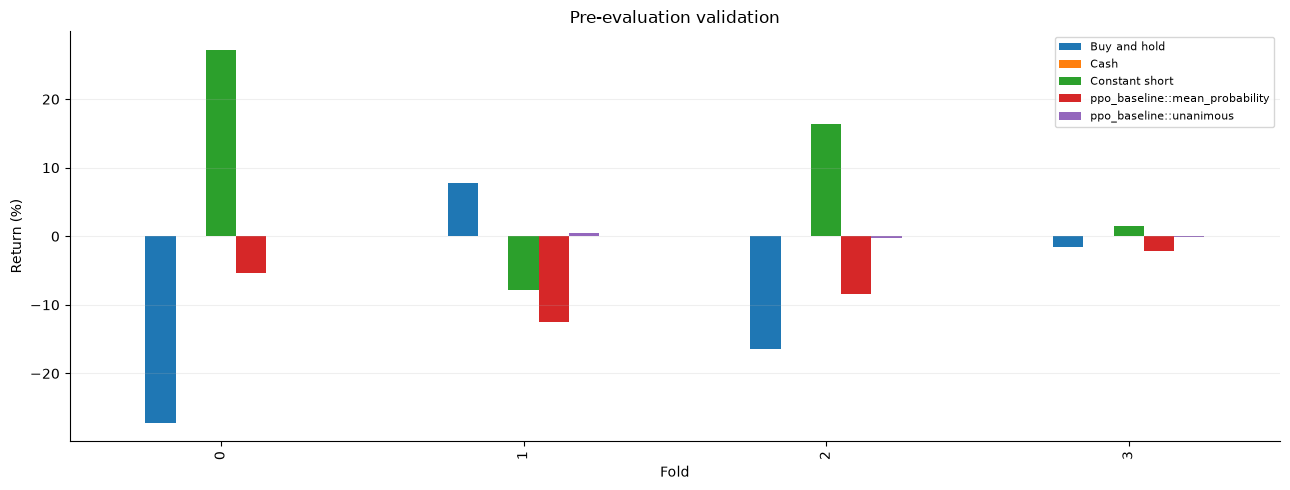

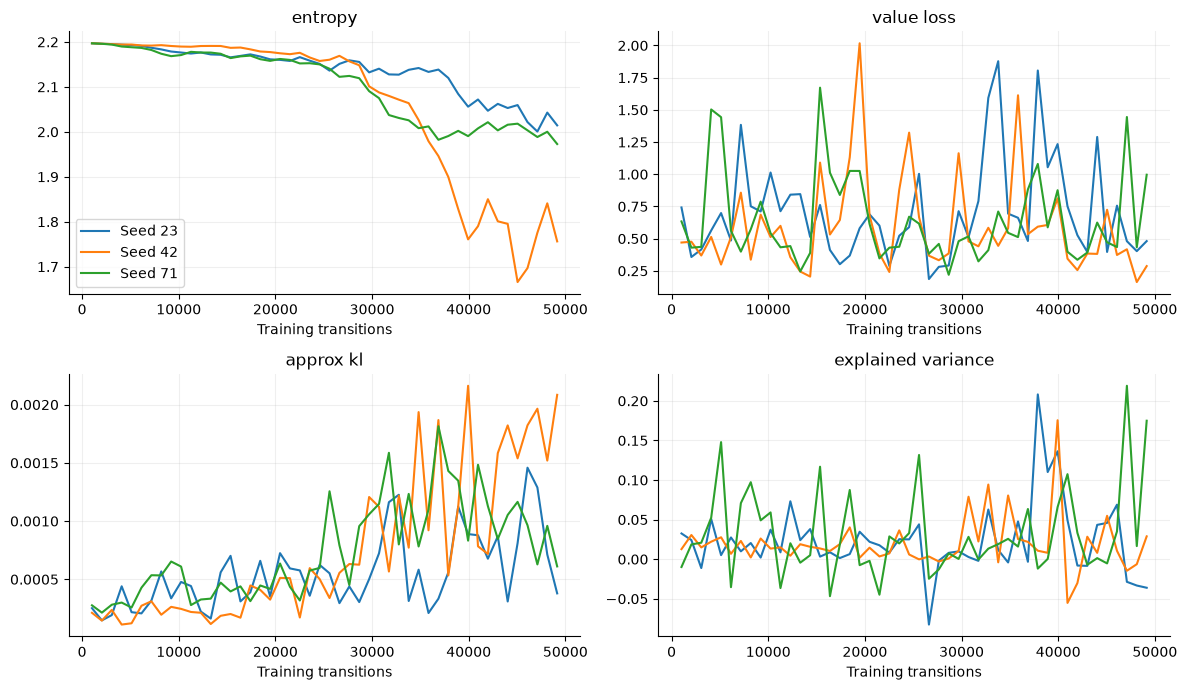

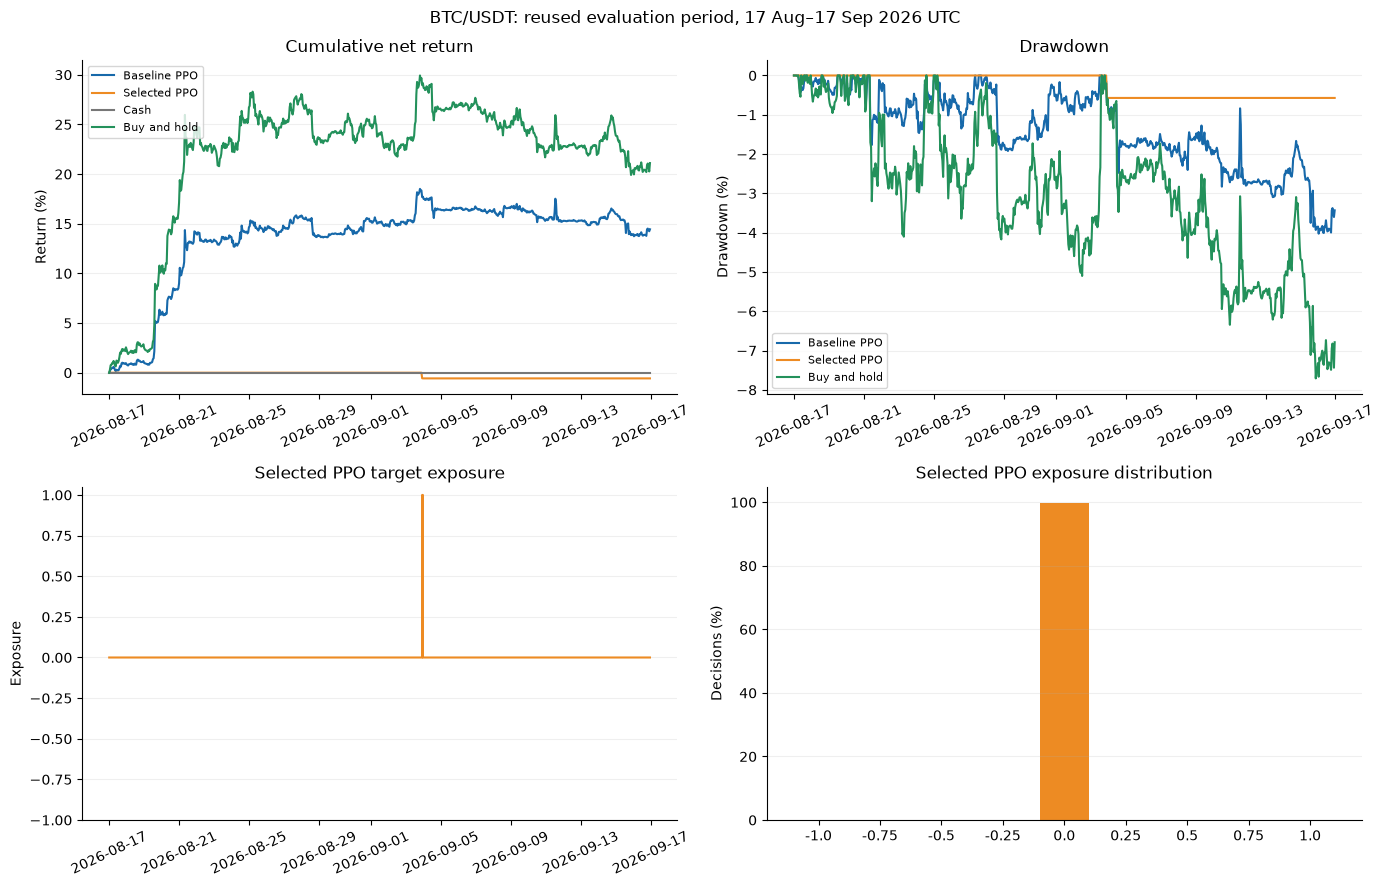

In [23]:
for name in ['screening_summary','confirmation_individual_summary','ensemble_summary']:
    display(experiment['tables'][name].round(5))
display(experiment['tables']['final_seed_results'][
    ['policy','seed','portfolio_return','max_drawdown','action_changes']])
for name in ['validation_comparison','training_diagnostics','policy_comparison']:
    figure = experiment['figures'][name]
    display(figure)
    plt.close(figure)

## 12. Independent in-memory verification

Reconstruct the selected ensemble from a `BytesIO` round trip and reproduce its full backtest. Verify the trial grids, scalers, action mapping, and portfolio accounting against tables in memory. No checkpoint, result, configuration, or notebook file is opened.

In [24]:
assert experiment_protocol(raw)==experiment['protocol']
policy = PPOEnsemble.from_bytes(experiment['policy'].to_bytes())
assert policy.positions==POSITIONS and len(policy.agents)==len(SEEDS)
features = add_features(raw,policy.config.features)
evaluation = features.loc[(features.index>=EVAL_START)&(features.index<EVAL_END)]
metrics,trace = rollout(policy,evaluation,return_trace=True)
reference = experiment['tables']['evaluation_results']
assert len(reference)==10 and reference.steps.eq(743).all()
np.testing.assert_allclose(reference.portfolio_return,metrics['portfolio_return'],rtol=0,atol=1e-12)
np.testing.assert_allclose(metrics['total_reward'],metrics['log_return'],rtol=0,atol=1e-10)
assert len(trace)==744 and set(trace.position).issubset(POSITIONS)
training = features.loc[(features.index>=TRAIN_START)&(features.index<EVAL_START)]
for agent in policy.agents:
    assert agent.network.actor[-1].out_features==len(POSITIONS)
    np.testing.assert_allclose(agent.mean[:-2],training[agent.columns].mean(),rtol=1e-6)
    np.testing.assert_allclose(agent.std[:-2],training[agent.columns].std().clip(lower=1e-6),rtol=1e-6)
counts = {}
transitions = 0
for phase in ['screening','confirmation','final_members']:
    trials = experiment['tables'][phase+'_trials']
    assert not trials.duplicated(['config','fold','seed']).any()
    assert np.isfinite(trials.select_dtypes(include=np.number).to_numpy()).all()
    assert len(trials)==len(experiment['trials'][phase])
    counts[phase] = len(trials)
    transitions += int(trials.training_steps.sum())
assert counts['screening']==len(CONFIGS)*len(FOLDS)
assert counts['confirmation'] in [2*len(SEEDS)*len(FOLDS),3*len(SEEDS)*len(FOLDS)]
assert counts['final_members'] in [len(SEEDS),2*len(SEEDS)]
verification = {'tests_passed':test_result.testsRun,'trial_counts':counts,'training_transitions':transitions,
                'selected_config':policy.config.name,'aggregation':policy.aggregation,
                'portfolio_return':metrics['portfolio_return'],'max_drawdown':metrics['max_drawdown'],
                'cash_fraction':float(trace.position.iloc[1:].eq(0).mean()),
                'project_file_inputs':'none; Binance data downloaded directly into memory','artifact_storage':'memory only','status':'passed'}
experiment['verification'] = verification
display(verification)
print('PASS: all training, reporting, and model verification completed in memory.')

{'tests_passed': 19,
 'trial_counts': {'screening': 28, 'confirmation': 36, 'final_members': 3},
 'training_transitions': 2375680,
 'selected_config': 'ppo_baseline',
 'aggregation': 'unanimous',
 'portfolio_return': -0.005714268765780073,
 'max_drawdown': -0.005714268765780073,
 'cash_fraction': 0.9986541049798116,
 'project_file_inputs': 'none; Binance data downloaded directly into memory',
 'artifact_storage': 'memory only',
 'status': 'passed'}

PASS: all training, reporting, and model verification completed in memory.


## Interpretation and in-memory objects

`raw` contains Binance candles and source metadata. `experiment` contains every model payload and history (`trials`), all result tables (`tables`), selected live models (`policy`, `baseline`), evaluation traces (`traces`), plots (`figures`), the report (`report`), and verification results (`verification`). These are ordinary Python objects and can be inspected directly in subsequent cells.

**Mean probability:** average the three models' nine action probabilities and choose the largest average. **Unanimous vote:** take a non-cash action only when all three models choose exactly that action; otherwise choose cash. Neither rule averages the exposure values.



## 13. Export the final selected agent with the provided evaluator

Run this cell after training has created `experiment['policy']`. It evaluates the configuration and aggregation rule selected on validation, over the same fixed evaluation period. It does not choose a new policy using evaluation returns.

The provided `evaluate_agent` interface and six CSV columns are preserved. Two compatibility adjustments access custom TradingEnv methods through `env.unwrapped` and refresh metrics after a manual `max_steps` cutoff. TradingEnv formats returns to two decimal percentage places before conversion, so exported returns have that rounding; `total_reward` retains its original precision.

The default call writes **`evaluation_results.csv` to the notebook kernel's working directory**, replacing that file when rerun.

In [29]:
def evaluate_agent(agent, env, num_episodes=10, max_steps=None, render=True,
                   csv_path="evaluation_results.csv", renderer_logs_dir="render_logs"):
    """Evaluate a frozen agent and export the provided six-column submission CSV."""
    if not isinstance(num_episodes, int) or num_episodes < 1:
        raise ValueError("num_episodes must be a positive integer")
    if max_steps is not None and (not isinstance(max_steps, int) or max_steps < 1):
        raise ValueError("max_steps must be None or a positive integer")

    # Gymnasium wrappers do not expose TradingEnv's custom metric/render methods.
    metrics_env = env.unwrapped
    results = []
    for ep in range(num_episodes):
        obs, info = env.reset()
        done = False
        truncated = False
        step = 0
        reward_total = 0.0
        while not done and not truncated:
            action = agent.choose_action_eval(obs)
            obs, reward, done, truncated, info = env.step(action)
            reward_total += float(reward)
            step += 1
            if (max_steps is not None) and (step >= max_steps):
                break

        # A manual cutoff does not trigger TradingEnv's automatic metric update.
        metrics_env.calculate_metrics()
        metrics = metrics_env.get_metrics()
        port_ret = float(metrics["Portfolio Return"].strip('%')) / 100.0
        market_ret = float(metrics["Market Return"].strip('%')) / 100.0
        results.append({
            "episode": ep + 1,
            "portfolio_return": port_ret,
            "market_return": market_ret,
            "excess_return": port_ret - market_ret,
            "steps": step,
            "total_reward": reward_total,
        })
        if render:
            print(f"Eval Episode {ep+1}: Total Reward: {reward_total:.2f}, "
                  f"Portfolio Return: {port_ret:.2%}, Market Return: {market_ret:.2%}, "
                  f"Excess Return: {(port_ret-market_ret):.2%}, Steps: {step}")
            time.sleep(1)
            metrics_env.save_for_render(dir=renderer_logs_dir)

    df_results = pd.DataFrame(results)
    df_results.to_csv(csv_path, index=False)
    print(f"Saved submission to {csv_path}")
    return df_results


if 'experiment' not in globals() or 'policy' not in experiment:
    raise RuntimeError("Run the training cells first to create experiment['policy'].")

submission_agent = experiment['baseline']
assert submission_agent.config == CONFIGS[0]
assert submission_agent.aggregation == 'mean_probability'
submission_features = add_features(raw, submission_agent.config.features)
submission_frame = submission_features.loc[
    (submission_features.index >= EVAL_START) & (submission_features.index < EVAL_END)]
assert len(submission_frame) == 744
assert (submission_frame.index[1:] - submission_frame.index[:-1] == pd.Timedelta(hours=1)).all()
print('Exporting validation-selected policy:', submission_agent.config.name,
      '| aggregation:', submission_agent.aggregation)
submission_env = make_env(submission_frame, submission_agent.positions)
try:
    submission_results = evaluate_agent(
        submission_agent, submission_env, num_episodes=10, max_steps=None,
        render=False, csv_path="evaluation_results.csv", renderer_logs_dir="render_logs")
finally:
    submission_env.close()

experiment['tables']['submission_results'] = submission_results
assert list(submission_results.columns) == [
    'episode', 'portfolio_return', 'market_return', 'excess_return', 'steps', 'total_reward']
assert submission_results.episode.tolist() == list(range(1, 11))
assert submission_results.steps.eq(len(submission_frame) - 1).all()
assert np.isfinite(submission_results.to_numpy()).all()
display(submission_results)


Exporting validation-selected policy: ppo_baseline | aggregation: mean_probability
Saved submission to evaluation_results.csv


,episode,portfolio_return,market_return,excess_return,steps,total_reward
0,1,0.1444,0.2112,-0.0668,743,0.134903
1,2,0.1444,0.2112,-0.0668,743,0.134903
2,3,0.1444,0.2112,-0.0668,743,0.134903
3,4,0.1444,0.2112,-0.0668,743,0.134903
4,5,0.1444,0.2112,-0.0668,743,0.134903
5,6,0.1444,0.2112,-0.0668,743,0.134903
6,7,0.1444,0.2112,-0.0668,743,0.134903
7,8,0.1444,0.2112,-0.0668,743,0.134903
8,9,0.1444,0.2112,-0.0668,743,0.134903
9,10,0.1444,0.2112,-0.0668,743,0.134903
